# Module 04 (part 2): Snow drought seen from space

*The code behind GEOS 212: Water in the West, Boise State University*

In the [first Module 04 notebook](04_snow_drought.ipynb) we used SNOTEL stations to show that WY2026 was a **warm snow drought** in the Boise Mountains: precipitation was close to normal, but much of it fell as rain or melted early, so the snowpack was far below normal.

But three stations are three points. Was WY2026's precipitation near normal across the whole region, or did we just happen to pick lucky stations? Satellites can answer that, because they see everywhere at once.

**Where are we in the water year?** In the *atmosphere* and the *snowpack*.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
import io, calendar
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import requests

try:
    import cartopy.crs as ccrs, cartopy.feature as cfeature
except ImportError:   # Google Colab doesn't include cartopy (map-drawing library); install it once
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cartopy"], check=True)
    import cartopy.crs as ccrs, cartopy.feature as cfeature

INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

def load_saved(name):
    """Load a saved NumPy data file (.npz) from this repository's data/ folder,
    or download it from GitHub if you're running in Colab."""
    local = DATA_DIR / name
    if local.exists():
        return np.load(local)
    r = requests.get(DATA_URL + name, timeout=120)
    r.raise_for_status()
    return np.load(io.BytesIO(r.content))

## About the data: NASA GPM IMERG

The **Global Precipitation Measurement (GPM)** mission is a joint NASA and Japan (JAXA) satellite mission launched in 2014. A "core" satellite carries a precipitation radar and a microwave imager, and it calibrates a constellation of about ten partner satellites. **IMERG** (Integrated Multi-satellitE Retrievals for GPM) merges all of them, plus rain-gauge data, into one map of precipitation every half hour on a 0.1° grid (about 10 km), back to June 2000.

Downloading IMERG requires a free NASA Earthdata account, so to keep this notebook simple we load a copy of the data that we already downloaded and summarized. The last section shows the code that downloads it, if you want to try with your own account.

**"Final" and "Late" runs.** NASA makes IMERG in stages. The *Late Run* comes out about 14 hours after the rain falls, using satellites only. The *Final Run* comes out about 3.5 months later and is corrected with monthly rain-gauge data, so it's more accurate. When we downloaded the data, the Final Run didn't cover all of WY2026 yet, so for WY2026 we use the Late Run, and correct it as explained below.

## 2. Loading the data

The saved file holds, for every 0.1° grid cell over the western US:
* `final_mm`: total precipitation for each water year, 2006-2025 (Final Run), in mm
* `late_wy2025_mm` and `late_wy2026_mm`: water-year totals from the Late Run

In [2]:
w = load_saved("gpm_west_wateryear_totals.npz")
lat, lon, years = w["lat"], w["lon"], w["years"]
final = w["final_mm"]                       # shape: (water year, lat, lon)
print("water years:", years.min(), "to", years.max(), "   grid:", final.shape[1:], "(lat, lon)")

# "Average" = the mean of water years 2006-2025 in each grid cell
average = final.mean(axis=0)

water years: 2006 to 2025    grid: (185, 210) (lat, lon)


## 3. Correcting the Late Run

The Late Run doesn't use rain gauges, so it can be biased, and the bias varies from place to place (satellites tend to struggle over snow-covered mountains). WY2025 is in *both* runs, so we can measure the bias there: the ratio Final ÷ Late, in each grid cell. Then we multiply the WY2026 Late Run by that ratio.

We smooth the ratio a little (averaging each cell with its neighbors) so one noisy grid cell doesn't throw off the correction. This is a simple version of what scientists call **bias correction**. It assumes the Late Run's errors in WY2026 look like its errors in WY2025, which is a reasonable first guess but worth remembering.

In [3]:
from scipy.ndimage import uniform_filter     # moving-window average over a 9 x 9 block of grid cells

final_2025 = final[years == 2025][0]
ratio = uniform_filter(final_2025, 9) / np.maximum(uniform_filter(w["late_wy2025_mm"], 9), 1)
wy2026 = w["late_wy2026_mm"] * ratio
wy2023 = final[years == 2023][0]

# The Boise Mountains: a box around the upper Boise River basin
box = (lat[:, None] > 43.2) & (lat[:, None] < 44.4) & (lon[None, :] > -116.4) & (lon[None, :] < -114.6)
for name, p in [("WY2023", wy2023), ("WY2026 (Late Run, raw)", w["late_wy2026_mm"]), ("WY2026 (corrected)", wy2026)]:
    print(f"Boise Mountains, {name}: {p[box].mean():.0f} mm = {100 * p[box].mean() / average[box].mean():.0f}% of average")

Boise Mountains, WY2023: 559 mm = 114% of average
Boise Mountains, WY2026 (Late Run, raw): 434 mm = 89% of average
Boise Mountains, WY2026 (corrected): 513 mm = 105% of average


## 4. Mapping percent of average

Now the map: each water year's precipitation as a percent of the 2006-2025 average. Browns are drier than average, blues are wetter.

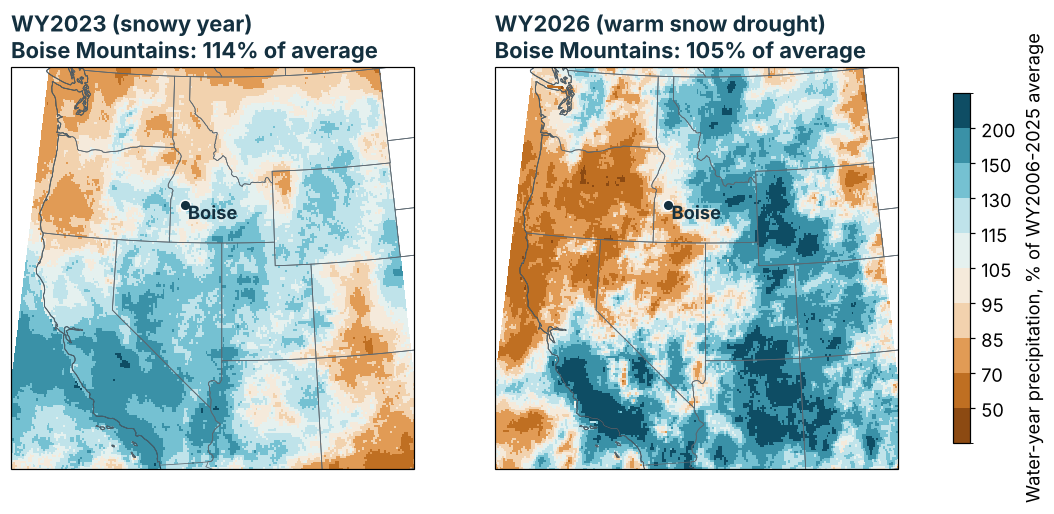

In [4]:
div_cmap = mcolors.LinearSegmentedColormap.from_list(
    "div", ["#8C4A12", OCHRE, "#F2D2AE", "#F7F7F2", "#BFE3EA", GLACIER, DEEP])
levels = [0, 50, 70, 85, 95, 105, 115, 130, 150, 200, 400]

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), subplot_kw=dict(projection=ccrs.LambertConformal(-114, 40)))
for ax, p, title in [(axs[0], wy2023, "WY2023 (snowy year)"), (axs[1], wy2026, "WY2026 (warm snow drought)")]:
    pct = 100 * p / np.maximum(average, 1)
    im = ax.pcolormesh(lon, lat, pct, cmap=div_cmap, norm=mcolors.BoundaryNorm(levels, div_cmap.N),
                       transform=ccrs.PlateCarree())
    ax.set_extent([-124.5, -104.5, 32, 49], ccrs.PlateCarree())
    ax.coastlines("50m", lw=0.6, color=INK)
    ax.add_feature(cfeature.STATES.with_scale("50m"), lw=0.5, edgecolor=BASALT)
    ax.plot(-116.2, 43.6, "o", ms=7, mfc=INK, mec="white", transform=ccrs.PlateCarree())
    ax.text(-116.0, 43.0, "Boise", color=INK, fontweight="bold", transform=ccrs.PlateCarree())
    ax.set_title(f"{title}\nBoise Mountains: {100 * p[box].mean() / average[box].mean():.0f}% of average",
                 loc="left", fontweight="bold", color=INK)
fig.colorbar(im, ax=axs, shrink=0.75, ticks=levels[1:-1], label="Water-year precipitation, % of WY2006-2025 average")

**Read the maps.** In WY2026, much of Oregon, northern Nevada and the Snake River Plain right around Boise were dry. But look at the mountains just north and east of Boise, where the Boise River's snow accumulates: they were close to average. SNOTEL told the same story in the first Module 04 notebook: April 1 precipitation at our three stations was 76-96% of median, but April 1 SWE at Bogus Basin was only about 30% of median. Near-normal precipitation with a tiny snowpack means the precipitation didn't stay as snow. That's the signature of a *warm* snow drought, and the satellite view shows the mountains really did get their water, not just our three stations.

Notice also that the satellite and the stations don't have to agree exactly: a 10 km grid cell averages over valleys and ridges, while a SNOTEL station measures one spot.

## 5. Where did the snow stay? MODIS snow cover by elevation

Precipitation was near normal, so where did the snow go? NASA's **MODIS** sensor (on the Terra satellite) maps snow cover every day at 500 m resolution. Using the cloud-gap-filled product for **April 1** of each year, together with a digital elevation model, we sorted the ground in the same Boise Mountains box by elevation and calculated the percent that was snow-covered in each 250 m elevation band. (The raw MODIS files need an Earthdata login, so we saved the summary table.)

April 1, 2023: half the ground snow-covered at about 4,023 ft
April 1, 2026: half the ground snow-covered at about 6,682 ft


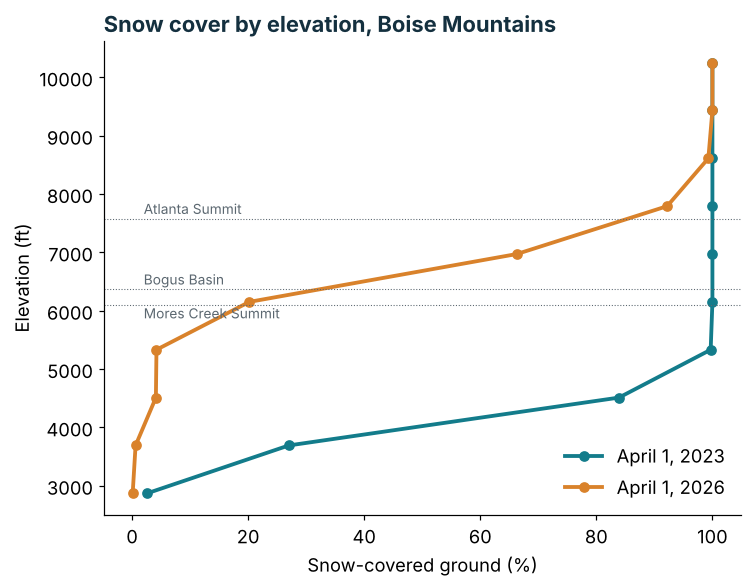

In [5]:
import pandas as pd
name = "modis_snow_apr1_by_elev.csv"
local = DATA_DIR / name
modis = pd.read_csv(local if local.exists() else DATA_URL + name)
modis["mid_ft"] = (modis.elev_lo_m + modis.elev_hi_m) / 2 * 3.281
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(modis.snow_pct_2023_04_01, modis.mid_ft, "o-", color=RIVER, lw=2.5, label="April 1, 2023")
ax.plot(modis.snow_pct_2026_04_01, modis.mid_ft, "o-", color=OCHRE, lw=2.5, label="April 1, 2026")
for station, elev, dy in [("Mores Creek Summit", 6100, -230), ("Bogus Basin", 6370, 80), ("Atlanta Summit", 7580, 80)]:
    ax.axhline(elev, color=BASALT, lw=0.7, ls=":")
    ax.text(2, elev + dy, station, fontsize=9, color=BASALT)
ax.set_xlabel("Snow-covered ground (%)"); ax.set_ylabel("Elevation (ft)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Snow cover by elevation, Boise Mountains", loc="left", fontweight="bold", color=INK)
plt.tight_layout()

for col, yr in [("snow_pct_2023_04_01", 2023), ("snow_pct_2026_04_01", 2026)]:
    # elevation where snow cover crosses 50%, interpolating between band midpoints
    print(f"April 1, {yr}: half the ground snow-covered at about {np.interp(50, modis[col], modis.mid_ft):,.0f} ft")

The **snow line** (where half the ground is white) sat about 2,700 ft higher on April 1, 2026. Bogus Basin and Mores Creek Summit sit right at the 2026 snow line, while Atlanta Summit sits above it. That's what their April 1 SWE showed in the first Module 04 notebook: the higher the station, the less the warm winter hurt.

## 6. Your turn

1. **Twenty years at a glance.** Make a bar chart of Boise Mountains precipitation for every water year 2006-2025 as % of average (loop over `years` and use `final[i][box].mean()`). Where do WY2023 and WY2026 rank?
2. **How much did the correction matter?** Re-draw the WY2026 map using the raw Late Run (`w["late_wy2026_mm"]`). Where does the correction change the picture most? Why might satellites underestimate precipitation over mountains in winter?
3. **Another basin.** Move the box to another snow-fed basin you care about, say the upper Colorado River (39-41° N, 105.5-107.5° W) or the Sierra Nevada (37-39.5° N, 119-121° W). Was WY2026 dry or warm there?

### Why code?
A few lines of NumPy turned 20 years of satellite precipitation data for about 39,000 grid cells into a bias-corrected map and a regional number, and moving to a different basin is a one-line change.

## Optional: download the data yourself

Want to get IMERG directly from NASA? Make a free account at [urs.earthdata.nasa.gov](https://urs.earthdata.nasa.gov/), generate a *token* (under "Generate Token"), and paste it below. The cell asks NASA's GES DISC data server for one month of precipitation over the western US, using a web address that requests just the slice of the global grid we want (this is called **OPeNDAP** subsetting, and it saves downloading the whole globe).

It's set to `RUN_DOWNLOAD = False` so the notebook works without an account.

In [6]:
RUN_DOWNLOAD = False
EARTHDATA_TOKEN = "paste-your-token-here"

if RUN_DOWNLOAD:
    import xarray as xr   # reads the netCDF file NASA sends back
    year, month = 2023, 1
    url = ("https://gpm1.gesdisc.eosdis.nasa.gov/opendap/GPM_L3/GPM_3IMERGM.07/"
           f"{year}/3B-MO.MS.MRG.3IMERG.{year}{month:02d}01-S000000-E235959.{month:02d}.V07B.HDF5.dap.nc4"
           # grid indices: lon = -179.95 + 0.1*i, lat = -89.95 + 0.1*j  (western US box)
           "?dap4.ce=/precipitation[0][550:759][1210:1394];/lat[1210:1394];/lon[550:759]")
    r = requests.get(url, headers={"Authorization": f"Bearer {EARTHDATA_TOKEN}"}, timeout=180)
    r.raise_for_status()
    ds = xr.open_dataset(io.BytesIO(r.content))
    rate = ds.precipitation.values[0].T                     # mm per hour, shape (lat, lon)
    total = rate * 24 * calendar.monthrange(year, month)[1]  # mm for the month
    plt.pcolormesh(ds.lon, ds.lat, total, cmap="Blues"); plt.colorbar(label="mm")
    plt.title(f"IMERG precipitation, {year}-{month:02d}")

---
*Data: NASA GPM IMERG V07 Final Run monthly (GPM_3IMERGM.07, doi:10.5067/GPM/IMERG/3B-MONTH/07) and Late Run daily (GPM_3IMERGDL.07, doi:10.5067/GPM/IMERGDL/DAY/07), NASA GES DISC. WY2026 values are from the Late Run with a bias correction and are preliminary.*